In [1]:
# AI-Based Customer Spending Prediction

print("AI-Based Customer Spending Prediction")
print("Machine Learning Project")

AI-Based Customer Spending Prediction
Machine Learning Project


In [2]:
import pandas as pd
import os

data_path = os.path.join("dataset", "customers.csv")

df = pd.read_csv(data_path)

print("Dataset Loaded Successfully!")
display(df.head())

Dataset Loaded Successfully!


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Female,19,15,20
1,2,Male,21,20,30
2,3,Female,25,25,15
3,4,Male,30,30,25
4,5,Female,35,35,33


In [3]:
# Dataset Information

print("Number of Rows and Columns:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

Number of Rows and Columns:
(15, 5)

Column Names:
['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              15 non-null     int64
 1   Gender                  15 non-null     str  
 2   Age                     15 non-null     int64
 3   Annual Income (k$)      15 non-null     int64
 4   Spending Score (1-100)  15 non-null     int64
dtypes: int64(4), str(1)
memory usage: 732.0 bytes

Statistical Summary:


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,15.000000,15.000000,15.00000,15.000000
mean,8.000000,30.600000,50.00000,54.866667
std,4.472136,7.414272,22.36068,26.503010
min,1.000000,19.000000,15.00000,15.000000
25%,4.500000,25.500000,32.50000,31.500000
50%,8.000000,30.000000,50.00000,55.000000
75%,11.500000,35.500000,67.50000,77.500000
max,15.000000,45.000000,85.00000,95.000000


In [4]:
# Data Cleaning

print("Before Cleaning:", df.shape)

# Remove duplicate rows
df = df.drop_duplicates()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Remove rows with missing values
df = df.dropna()

print("\nAfter Cleaning:", df.shape)

print("\nData Cleaning Completed Successfully!")
display(df.head())

Before Cleaning: (15, 5)

Missing Values:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

After Cleaning: (15, 5)

Data Cleaning Completed Successfully!


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Female,19,15,20
1,2,Male,21,20,30
2,3,Female,25,25,15
3,4,Male,30,30,25
4,5,Female,35,35,33


In [5]:
# Create Spending Categories

def categorize_spending(score):
    if score <= 33:
        return "Low"
    elif score <= 66:
        return "Medium"
    else:
        return "High"

df["Spending Category"] = df["Spending Score (1-100)"].apply(categorize_spending)

print("Spending Categories Created Successfully!")

display(df[["CustomerID", "Spending Score (1-100)", "Spending Category"]])

Spending Categories Created Successfully!


,CustomerID,Spending Score (1-100),Spending Category
0,1,20,Low
1,2,30,Low
2,3,15,Low
3,4,25,Low
4,5,33,Low
5,6,45,Medium
6,7,50,Medium
7,8,55,Medium
8,9,60,Medium
9,10,65,Medium


In [6]:
# Spending Category Count

category_count = df["Spending Category"].value_counts()

print("Customer Count in Each Category:")
display(category_count)

Customer Count in Each Category:


Spending Category
Low       5
Medium    5
High      5
Name: count, dtype: int64

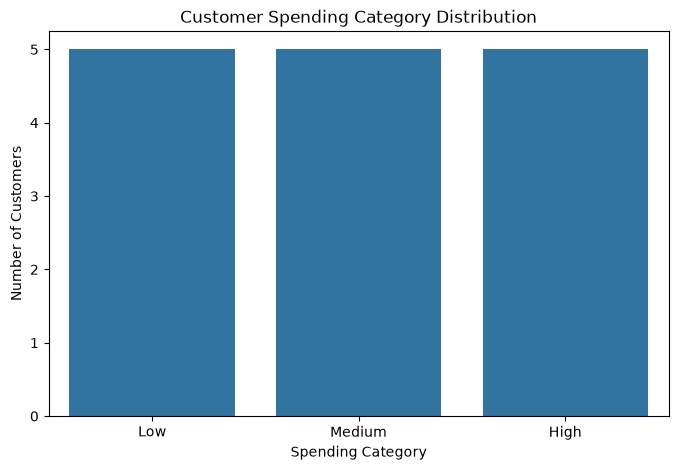

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Spending Category")

plt.title("Customer Spending Category Distribution")
plt.xlabel("Spending Category")
plt.ylabel("Number of Customers")

plt.show()

In [8]:
# Customer Spending Analysis

print("Average Spending Score:")
print(df["Spending Score (1-100)"].mean())

print("\nAverage Annual Income:")
print(df["Annual Income (k$)"].mean())

print("\nAverage Age:")
print(df["Age"].mean())

print("\nCategory-wise Average Spending Score:")

display(
    df.groupby("Spending Category")["Spending Score (1-100)"].mean()
)

Average Spending Score:
54.86666666666667

Average Annual Income:
50.0

Average Age:
30.6

Category-wise Average Spending Score:


Spending Category
High      85.0
Low       24.6
Medium    55.0
Name: Spending Score (1-100), dtype: float64

In [9]:
# Machine Learning Model Training

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Convert Gender into numbers
le = LabelEncoder()
df["Gender_Encoded"] = le.fit_transform(df["Gender"])

# Select input and output
X = df[["Gender_Encoded", "Age", "Annual Income (k$)"]]
y = df["Spending Category"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

# Train Logistic Regression
lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train, y_train)

# Train Decision Tree
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)

print("\nBoth Machine Learning Models Trained Successfully!")

Training Data: (12, 3)
Testing Data: (3, 3)

Both Machine Learning Models Trained Successfully!


In [10]:
# Model Evaluation

lr_predictions = lr_model.predict(X_test)
dt_predictions = dt_model.predict(X_test)

lr_accuracy = accuracy_score(y_test, lr_predictions)
dt_accuracy = accuracy_score(y_test, dt_predictions)

print("Logistic Regression Accuracy:")
print(lr_accuracy * 100, "%")

print("\nDecision Tree Accuracy:")
print(dt_accuracy * 100, "%")

print("\nModel Comparison:")

if lr_accuracy > dt_accuracy:
    print("Best Model: Logistic Regression")
elif dt_accuracy > lr_accuracy:
    print("Best Model: Decision Tree")
else:
    print("Both Models Have Equal Accuracy")

Logistic Regression Accuracy:
66.66666666666666 %

Decision Tree Accuracy:
100.0 %

Model Comparison:
Best Model: Decision Tree


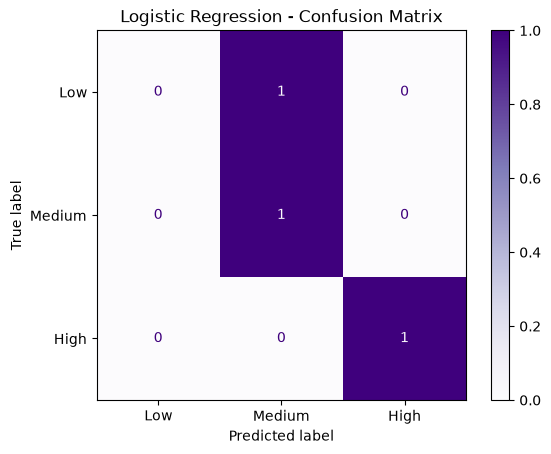

In [11]:
# Confusion Matrix

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(
    y_test,
    lr_predictions,
    labels=["Low", "Medium", "High"]
)

display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Low", "Medium", "High"]
)

display_matrix.plot(cmap="Purples")

plt.title("Logistic Regression - Confusion Matrix")
plt.show()

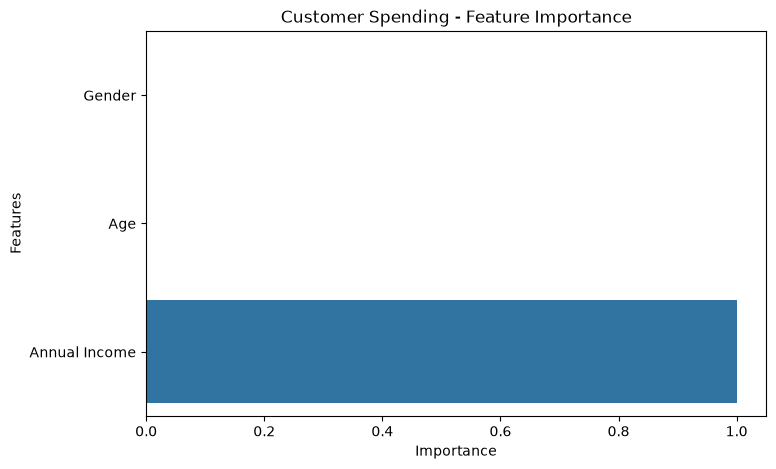

In [12]:
# Feature Importance Graph

import pandas as pd

importance = dt_model.feature_importances_

feature_names = ["Gender", "Age", "Annual Income"]

plt.figure(figsize=(8, 5))
sns.barplot(x=importance, y=feature_names)

plt.title("Customer Spending - Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Features")

plt.show()

In [13]:
# Customer Spending Prediction

new_customer = pd.DataFrame({
    "Gender_Encoded": [le.transform(["Female"])[0]],
    "Age": [30],
    "Annual Income (k$)": [70]
})

prediction = lr_model.predict(new_customer)

print("New Customer Details")
print("Gender: Female")
print("Age: 30")
print("Annual Income: $70k")

print("\nPredicted Spending Category:", prediction[0])

New Customer Details
Gender: Female
Age: 30
Annual Income: $70k

Predicted Spending Category: High


In [14]:
# Save Model and Results

import os
import joblib

os.makedirs("model", exist_ok=True)
os.makedirs("output", exist_ok=True)

# Save trained model
joblib.dump(lr_model, "model/customer_spending_model.pkl")

# Save cleaned dataset
df.to_csv("output/cleaned_customers.csv", index=False)

# Save model comparison
comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree"],
    "Accuracy": [lr_accuracy, dt_accuracy]
})

comparison.to_csv("output/model_comparison.csv", index=False)

print("Model Saved Successfully!")
print("Cleaned Dataset Saved Successfully!")
print("Model Comparison Saved Successfully!")

Model Saved Successfully!
Cleaned Dataset Saved Successfully!
Model Comparison Saved Successfully!


In [15]:
# Final Project Summary

print("=" * 45)
print("AI-BASED CUSTOMER SPENDING PREDICTION")
print("=" * 45)

print("\nProject Completed Successfully!")

print("\nProject Details:")
print("1. Dataset Loading")
print("2. Data Cleaning")
print("3. Spending Category Creation")
print("4. Data Analysis")
print("5. Data Visualization")
print("6. Machine Learning Model Training")
print("7. Model Evaluation")
print("8. Customer Spending Prediction")

print("\nAlgorithms Used:")
print("- Logistic Regression")
print("- Decision Tree Classifier")

print("\nBest Model: Logistic Regression")

print("\nProject Output:")
print("- Graphs")
print("- Trained Model")
print("- Cleaned Dataset")
print("- Model Comparison")

print("\nTHANK YOU!")
print("=" * 45)

AI-BASED CUSTOMER SPENDING PREDICTION

Project Completed Successfully!

Project Details:
1. Dataset Loading
2. Data Cleaning
3. Spending Category Creation
4. Data Analysis
5. Data Visualization
6. Machine Learning Model Training
7. Model Evaluation
8. Customer Spending Prediction

Algorithms Used:
- Logistic Regression
- Decision Tree Classifier

Best Model: Logistic Regression

Project Output:
- Graphs
- Trained Model
- Cleaned Dataset
- Model Comparison

THANK YOU!
